In [1]:
%load_ext autoreload
%autoreload 2

#### Case 1 : XANES + PDF 

This notebook runs through a simple example of the capabilities of Spectra-Scope. The imported data is simulated XANES and PDF of Ti-Oxide structures from the materials project database and Na Narong, *et al.* [1]. This notebook runs through regressing bond length for this dataset. The corresponding materials project ids can be found in the **TODO** file. 

**TODO** : Bug when running do_all --> original estimator might be getting refitted. Print statement says it already is, I then clone that estimator and that should fix it (in spectrascope/SpectraScope)

In [58]:
from spectrascope.SpectraScope import *
from spectrascope.features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import SPA 
from spectrascope.plot_spectral_features import * 

plt.style.use('../ss.mplstyle')

Load Test files 

In [51]:
fnX = '../tests/test_files/X_testfile.npy'
fny = '../tests/test_files/y_testfile.npy'
X = np.load(fnX)
y = np.load(fny)

print('The shape of the input file is:', X.shape)
print('X[0] accesses the PDF data. X[1] accesses the XANES data.\n')
print('The shape of the label file is:', y.shape)


The shape of the input file is: (2, 821, 200)
X[0] accesses the PDF data. X[1] accesses the XANES data.

The shape of the label file is: (821,)


Initialize Spectra-Scope object

In [37]:
ss = SpectraScope(X = X, y = y, specnames=['pdf', 'xanes'], yname='nn', random_seed=12)

saving to /examples/models, change save_path kwarg if youd like to change


Adding the x-axis values for each dataset

In [39]:
ss.add_x_axis(specname='xanes', value=np.linspace(4969.0, 5021.0, 200))
ss.add_x_axis(specname='pdf', value=np.linspace(0,10,200))

The `SpectraScope.add_spectral_feature` function generates a feature from the uploaded data. The feature is selected by the `feat` parameter. `pontwise_features` generates interpolated data along the x-axis. 

In [40]:
ss.add_spectral_feature(specname = 'xanes', feat = 'pointwise_features', xrange = ss.xanes_xaxis)
ss.add_spectral_feature(specname = 'pdf', feat = 'pointwise_features', xrange = ss.pdf_xaxis)

Here, we plot the first XANES/PDF from each dataset. 

Text(0, 0.5, '$\\mu(E)$')

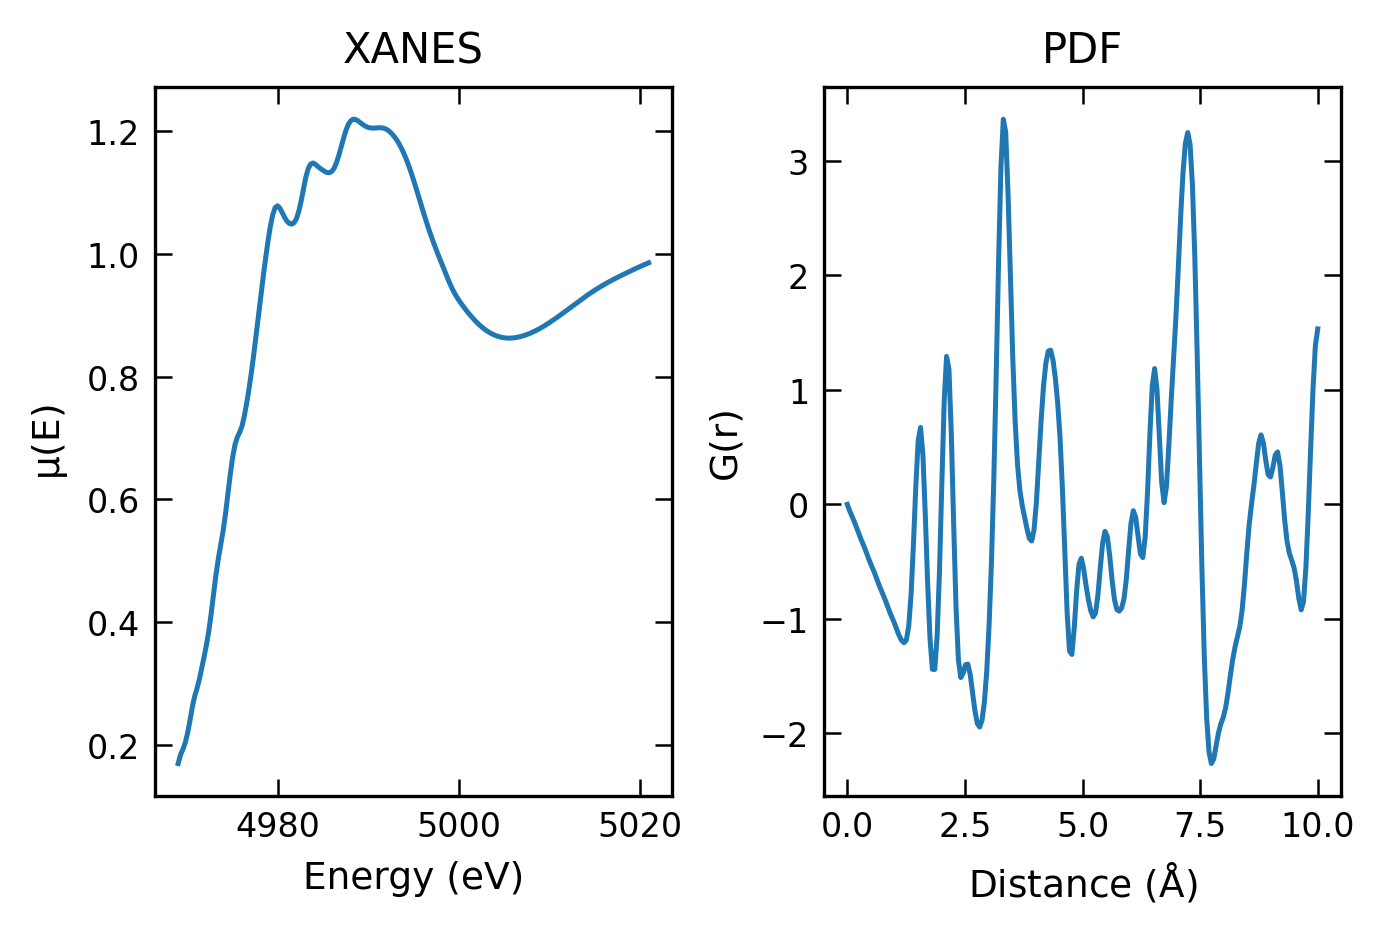

In [57]:
f, (ax1, ax2) = plt.subplots(1,2, constrained_layout=True)
ax1.plot(ss.xanes_xaxis, ss.xanes_pointwise_features[0])
ax2.plot(ss.pdf_xaxis, ss.pdf_pointwise_features[0])
ax1.set_title('XANES')
ax2.set_title('PDF')
ax1.set_xlabel('Energy (eV)')
ax2.set_xlabel(r'Distance ($\AA$)')
ax2.set_ylabel('G(r)')
ax1.set_ylabel(r'$\mu(E)$')


In [9]:
col = 'xanes'
spec = getattr(ss, f"{col}_pointwise_features")[0]
temp = SpectralFeatures(ss.xanes_xaxis, spec)

We will transform the different datasets in a variety of ways to compare model performance on different featurization schemes. Here, we featurize the XANES dataset in a variety of ways, again using the `SpectraScope.add_spectral_feature` function. 

In [59]:
ss.add_spectral_feature('xanes', 'polynomial_featuresall')
ss.add_spectral_feature('xanes', 'polynomial_featuresN', N=5)
ss.add_spectral_feature('xanes', 'featureagg', n_clusters=10)
ss.add_spectral_feature('xanes', 'pca', n_components=10)
ss.add_spectral_feature('xanes', 'cdf')
ss.add_spectral_feature('xanes', 'cwt')

Text(0.5, 0.98, 'XANES Featurization Schemes')

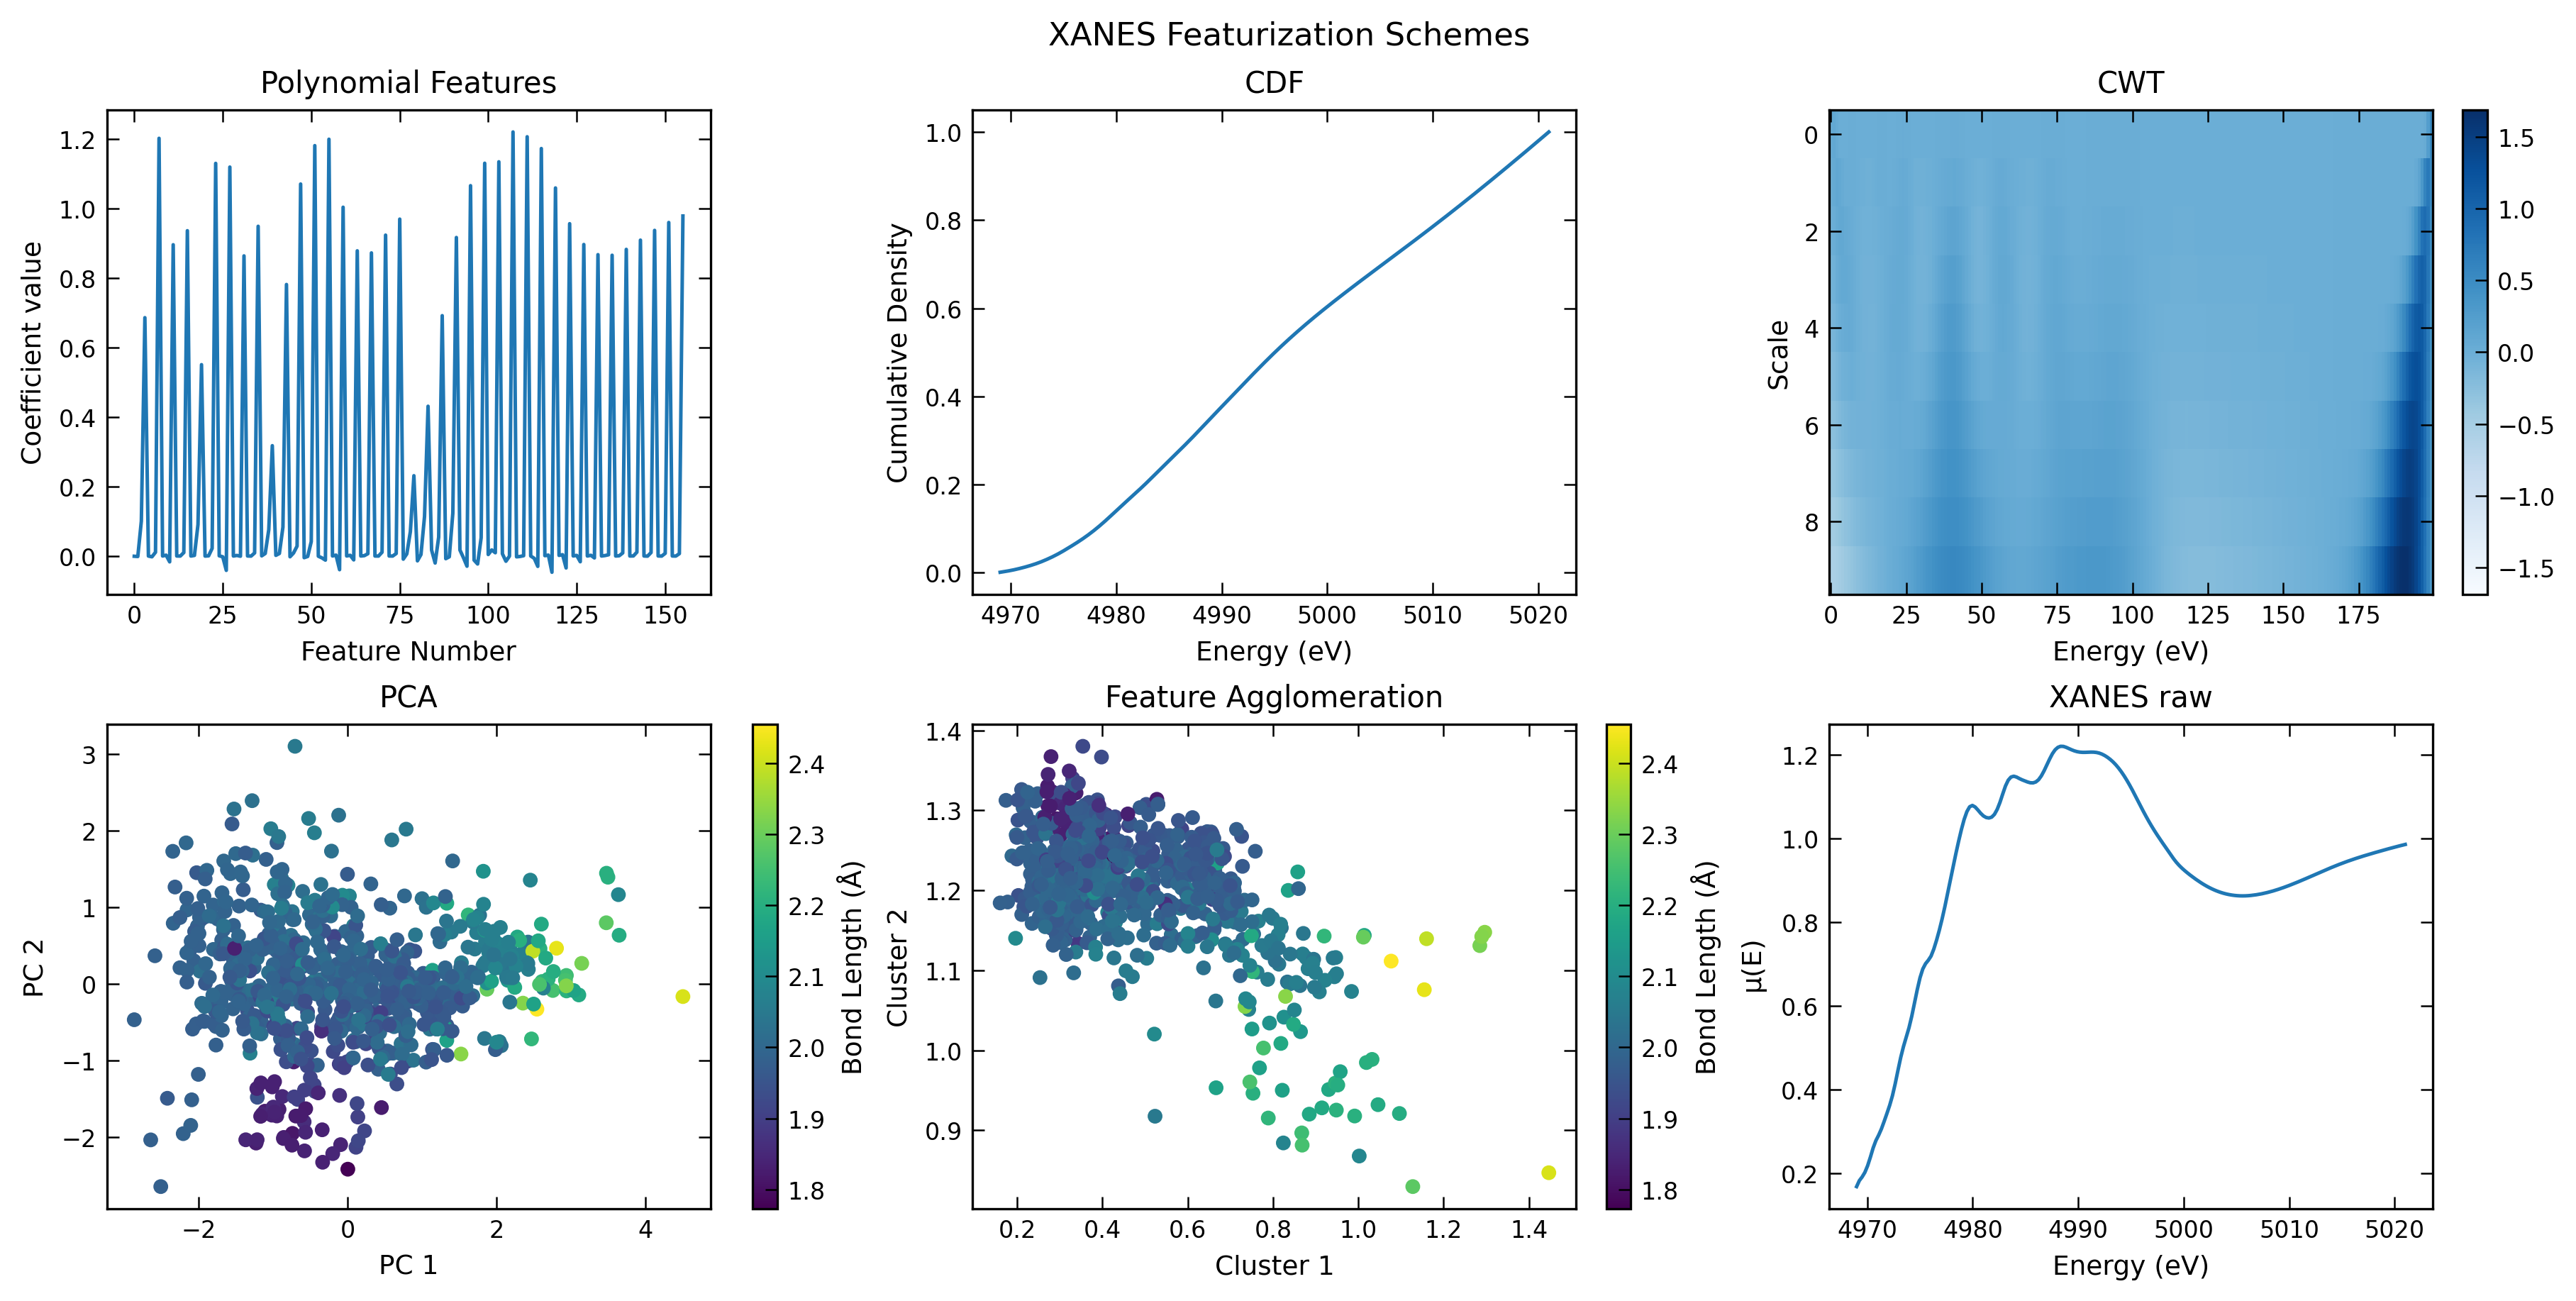

In [71]:
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2,3, figsize=(12,6), constrained_layout = True)
ax1.plot(np.arange(156), ss.xanes_polynomial_featuresall[0][:-1])
ax2.plot(ss.xanes_xaxis, ss.xanes_cdf[0])

cwt_coefs = ss.xanes_cwt[0]
im = ax3.imshow(cwt_coefs.reshape(10,200), aspect='auto', cmap='Blues',
                vmax=(np.abs(cwt_coefs)).max(), vmin=-(np.abs(cwt_coefs)).max())
f.colorbar(im, ax=ax3)


pc = ax4.scatter(ss.xanes_pca[:,0], ss.xanes_pca[:,1], c = ss.nn)
f.colorbar(pc, ax=ax4, label='Bond Length (Å)')
agg = ax5.scatter(ss.xanes_featureagg[:,0], ss.xanes_featureagg[:,1], c = ss.nn)
f.colorbar(agg, ax=ax5, label='Bond Length (Å)')
ax6.plot(ss.xanes_xaxis, ss.xanes[0])

ax1.set_title('Polynomial Features')
ax1.set_xlabel('Feature Number')
ax1.set_ylabel('Coefficient value')

ax2.set_title('CDF')
ax2.set_xlabel('Energy (eV)')
ax2.set_ylabel('Cumulative Density')

ax3.set_title('CWT')
ax3.set_xlabel('Energy (eV)')
ax3.set_ylabel('Scale')

ax4.set_title('PCA')
ax4.set_xlabel('PC 1')
ax4.set_ylabel('PC 2')

ax5.set_title('Feature Agglomeration')
ax5.set_xlabel('Cluster 1')
ax5.set_ylabel('Cluster 2')

ax6.set_title('XANES raw')
ax6.set_xlabel('Energy (eV)')
ax6.set_ylabel(r'$\mu(E)$')

f.suptitle('XANES Featurization Schemes')



We can concatenate different spectra and featurizations and perform model training on multi-modal datasets. Here, we combine the XANES and PDF interpolated data.

In [72]:
ss.combine_feature('xanes_pointwise_features', 'pdf_pointwise_features')

Text(0.5, 0.98, 'XANES + PDF, Concatenated')

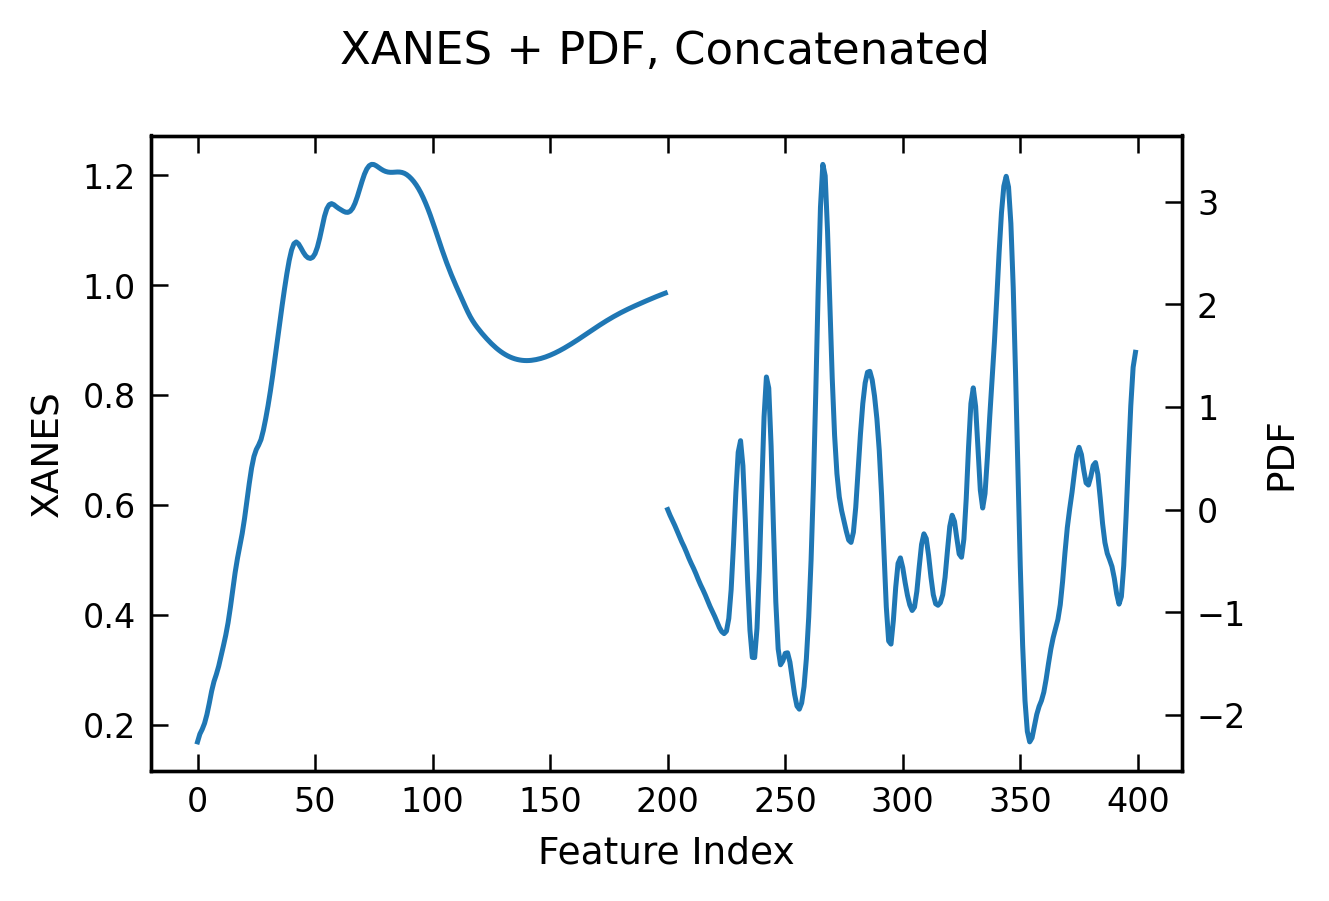

In [81]:
f, ax = plt.subplots(1,1)
ax_twinx = ax.twinx()

ax.plot(np.arange(200), ss.xanes_pdf_pointwise_features[0][:200])
ax_twinx.plot(np.arange(200,400), ss.xanes_pdf_pointwise_features[0][200:])

ax.set_xlabel('Feature Index')
ax.set_ylabel('XANES')
ax_twinx.set_ylabel('PDF')

f.suptitle('XANES + PDF, Concatenated')


Initialize hyperparameter grids for cross-validation with `sklearn.model_selection.GridSearchCV`

In [82]:
ridge_kwargs = {'estimator':Ridge(), 
                             'param_grid': {'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                                           'fit_intercept':[True], 
                            }, 'refit':True, 
                             'metric':mean_squared_error}
                             
                             
lasso_kwargs = {'estimator':Lasso(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'metric':mean_squared_error}

en_kwargs = {'estimator':ElasticNet(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'l1_ratio': [0.1, 0.5, 0.9],
                            'fit_intercept':[True]
                            },
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50,100,200, 300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [10,35, None]},
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [50, None]},
                'refit':True,
                'metric':mean_squared_error}

lcen_kwargs = {'l1_ratio':[0.01,0.1, 0.3, 0.5, 0.6, 0.99],
               'K_fold':5, 
               'cv_method':'Kfold', 
               'alpha':5, 
               'degree':[1],
               'trans_type':'poly', 
               'LCEN_cutoff':5e-2, 
               'LCEN_interaction':True, 
               'scale_X':True, 
               'scale_y':True}

Additionally, we use the SPA module to perform further nonlinear transformations of the XANES data such as sqrt and polynomial transformations. 

In [ ]:
# ss.transform_feature('xanes_pointwise_features', degree=2, interaction=False)
# BUG IN SPA : Can't run this twice? 

#### Model Training 
We set up the pipeline and do all of the training for the different features we created for both the XANES and PDF functions. We train both Random Forest and LCEN models. Each model and feature pair goes through hyperparameter tuning using `sklearn.model_selection.GridSearchCV`

In [ ]:
feats = {'pointwise_features':[{'specname':'xanes', 'xrange':ss.xanes_xaxis},
                               {'specname':'pdf', 'xrange':ss.pdf_xaxis}],
         'polynomial_featuresall':[
             { 'specname':'xanes', 'Narr':np.array([4,5,10,20]), 'degree':3},
             { 'specname':'pdf', 'Narr':np.array([4,5,10,20]), 'degree':3}], 
        'cdf': [{ 'specname':'xanes'}],
        'pca': [{ 'specname':'xanes'}, {'specname':'pdf'}],
        'featureagg': [{ 'specname':'xanes'}, {'specname':'pdf'}],
        'pointwise_features_trans' : [{'specname':'xanes'}]
         }
         
sk_kwargs = [RF_kwargs]
multi_modal = [('xanes_pointwise_features', 'pdf_pointwise_features'), 
               ('xanes_polynomial_featuresall', 'pdf_polynomial_featuresall')]

ss.do_all(feats, 'nn', 0.20, sk_kwargs=sk_kwargs, lcen_kwargs=lcen_kwargs, 
                multi_modal=multi_modal)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0433 | Mean relative error = 0.0144
Test set : RMSE = 0.0390 | Mean relative error = 0.0130
already fitted
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0557 | Mean relative error = 0.0189
Test set : RMSE = 0.0546 | Mean relative error = 0.0199
already fitted
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best

#### Benchmarking + Summarizing Performance 
Using simple heatmaps, we quickly visualize the performance of different model and feature pairs by comparing the RMSEs. We go through different statistics to compare to previous studies. 

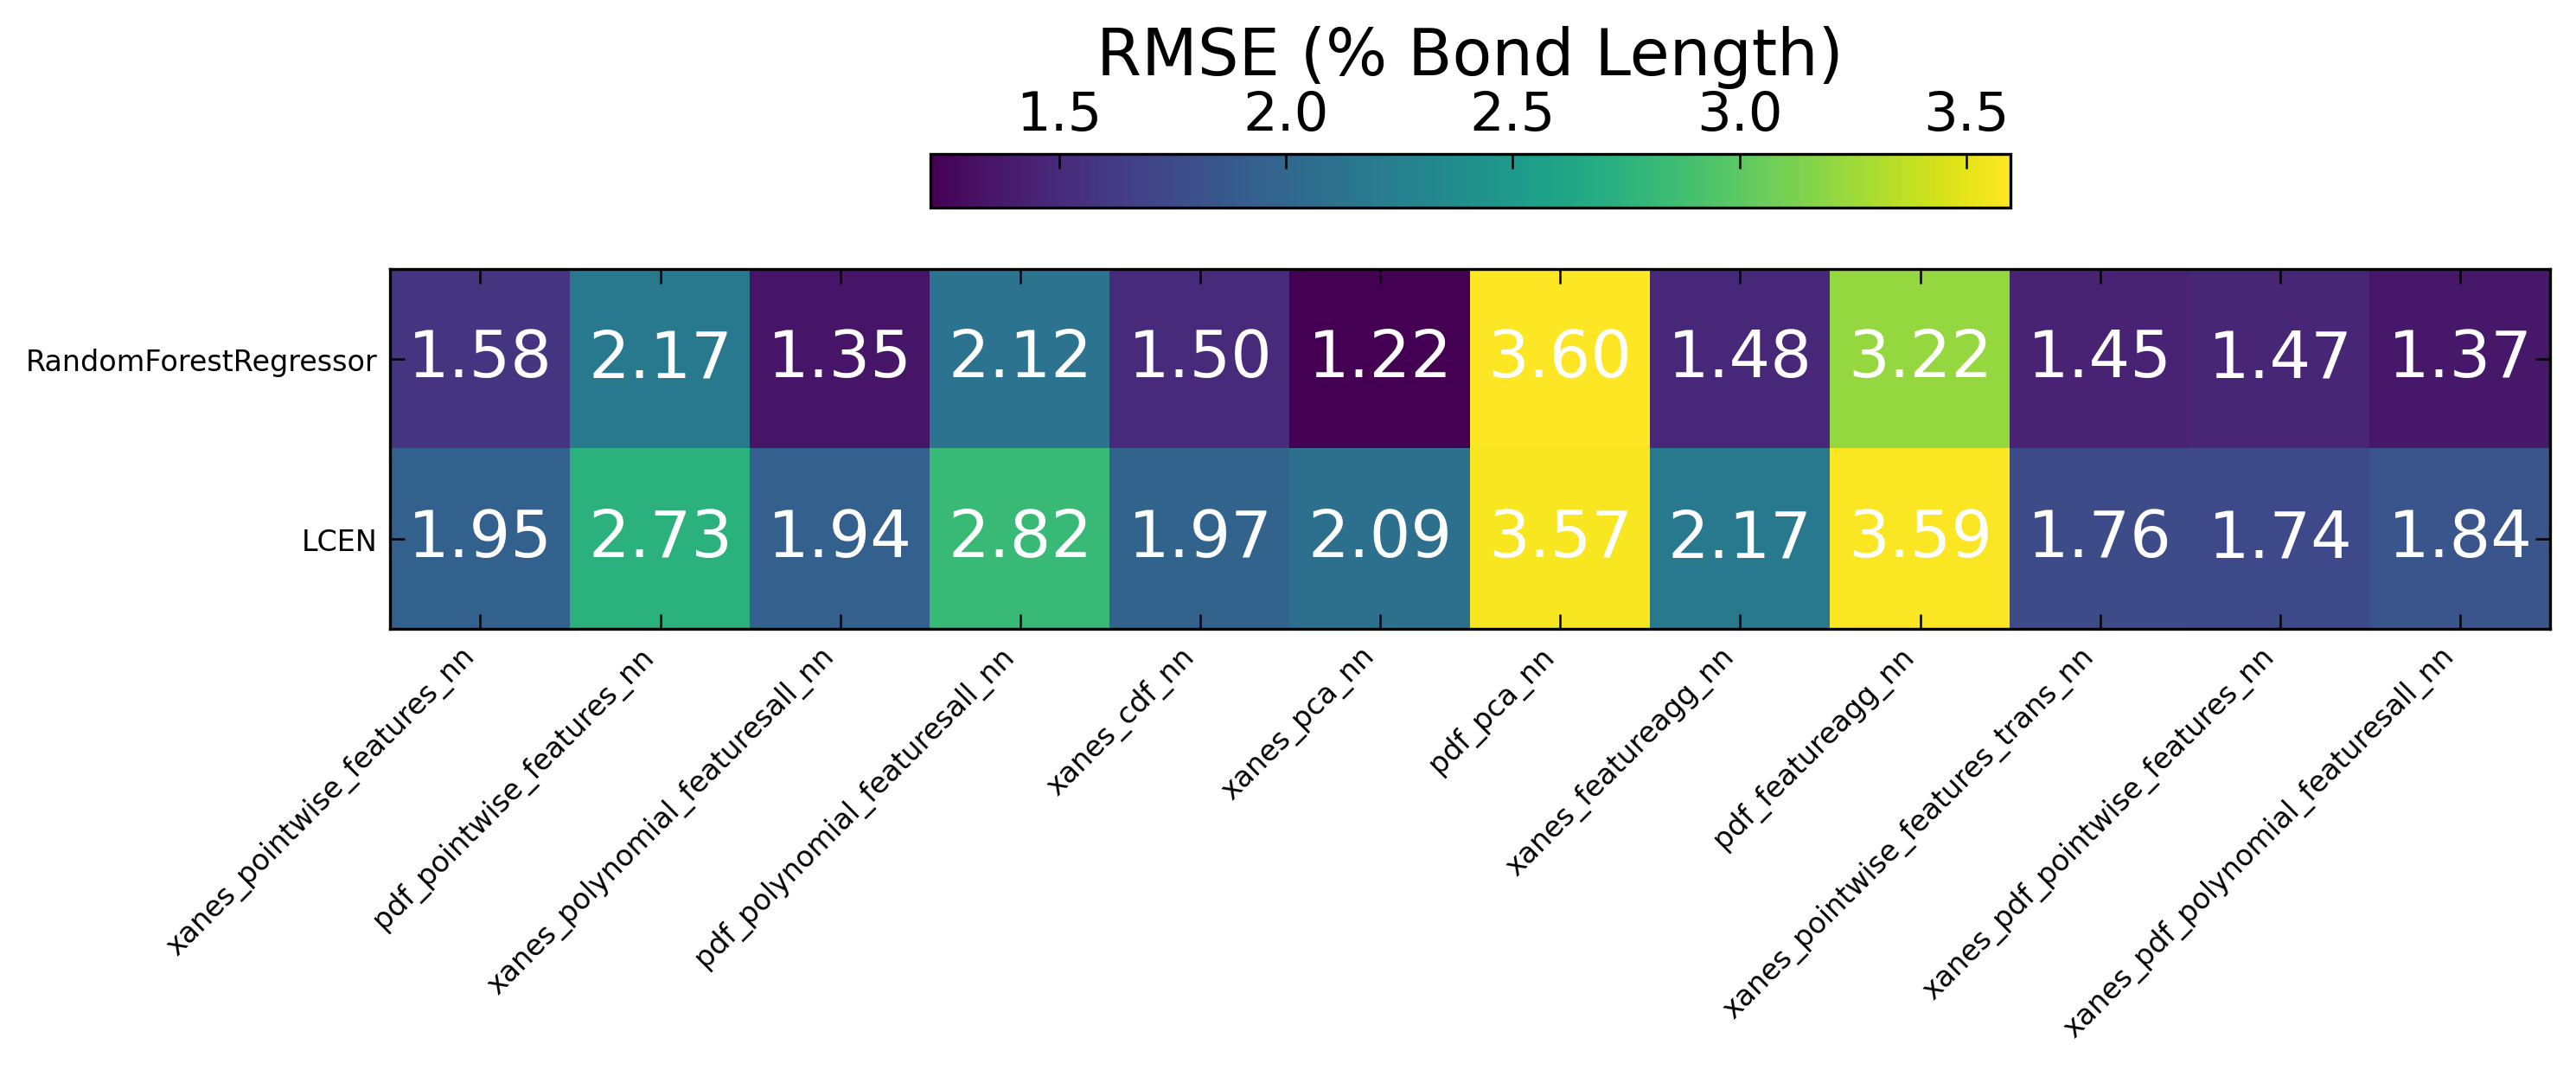

In [100]:
fontsize = 22
ticklabelsize = 18
xanes_color = '#2176ff'
pdf_color = '#d8315b'

results_df = pd.DataFrame(ss.best_fits).T # best fits given in MSE 
results_df = results_df.loc[['RandomForestRegressor', 'LCEN']]
results_df = np.sqrt(results_df)/np.mean(ss.nn) * 100 # % bond length


fig, (ax1) = plt.subplots(1,1, figsize=(10,5))
ylabels = results_df.index
xlabels = results_df.columns

im = ax1.imshow(results_df)

ax1.set_xticks(np.arange(len(xlabels)));
ax1.set_xticklabels(xlabels, rotation=45, ha='right');
cb1 = fig.colorbar(im, shrink=0.5, ax=ax1, location='top', label='RMSE')
cb1.ax.tick_params(labelsize=15)
cb1.set_label('RMSE (% Bond Length)', fontsize=18) 

ax1.set_yticks([0, 1])

for (i, j), val in np.ndenumerate(results_df):
    ax1.text(j, i, f'{val:.2f}', ha='center', va='center', color='white',size=ticklabelsize)
    
ax1.set_yticklabels(ylabels);

In [93]:
pdf_important_color = '#800016'
xanes_important_color = '#001242'

In [118]:
max_coords

(6, 0)

Minimum RMSE: 0.0243, with feature:: xanes_pca_nn, and model : RandomForestRegressor
Maximum RMSE: 0.0718, with feature pdf_pca_nn, and model : RandomForestRegressor


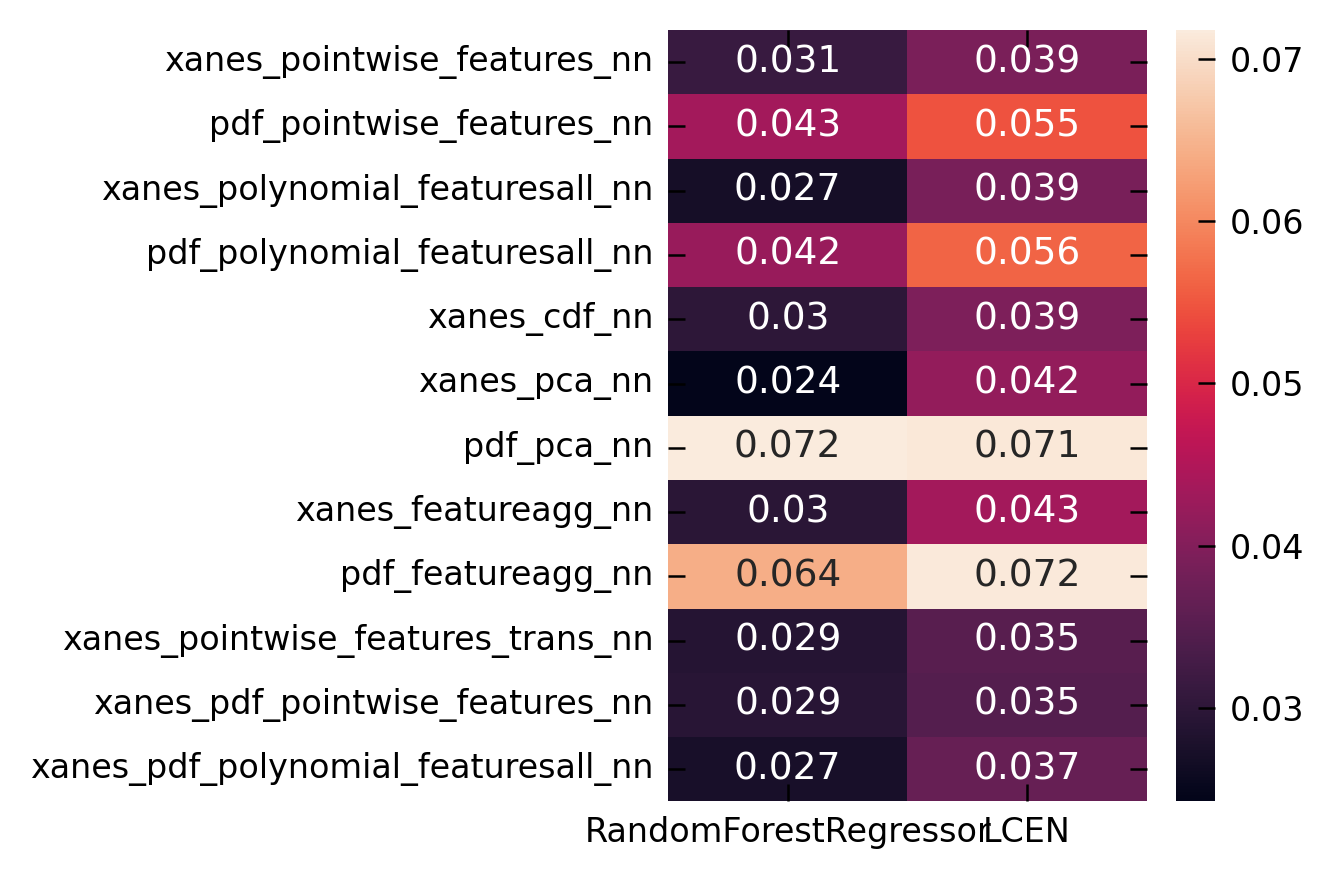

In [122]:
temp_df = np.sqrt(pd.DataFrame(ss.best_fits))[['RandomForestRegressor', 'LCEN']]

sns.heatmap(temp_df[['RandomForestRegressor', 'LCEN']], annot=True)
rmse_min = temp_df[['RandomForestRegressor', 'LCEN']].values.min()
rmse_max = temp_df[['RandomForestRegressor', 'LCEN']].values.max()


# Get the position of min value
min_coords = np.unravel_index(temp_df.values.argmin(), temp_df.shape) 
max_coords = np.unravel_index(temp_df.values.argmax(), temp_df.shape)
min_feat, min_col = temp_df.index[min_coords[0]], temp_df.columns[min_coords[1]]
max_feat, max_col = temp_df.index[max_coords[0]], temp_df.columns[max_coords[1]]

print(f"Minimum RMSE: {rmse_min:.4f}, with feature:: {min_feat}, and model : {min_col}")
print(f"Maximum RMSE: {rmse_max:.4f}, with feature {max_feat}, and model : {max_col}")


